Um distribuidor atacadista atende, ao mesmo tempo, clientes muito diferentes entre si: o restaurante que compra
hortifr´uti e congelados em alto giro, o pequeno mercado de bairro que se abastece de mercearia, latic´ınios e produtos
de limpeza, entre outros. Tratar todos eles com a mesma pol´ıtica comercial e, na pr ´ atica, desperdic¸ar margem e ´
capacidade log´ıstica.
A segmentac¸ao de clientes tem aplicac¸ ˜ oes diretas no planejamento de rotas e estoques, na definic¸ ˜ ao de campanhas ˜
promocionais dirigidas, na concessao de limites de cr ˜ edito e na identificac¸ ´ ao de clientes at ˜ ´ıpicos, que merecem
atendimento dedicado. No Brasil, o crescimento do modelo de atacarejo e a importancia dos distribuidores regionais ˆ
no abastecimento do interior do Nordest, tornam o problema especialmente concreto para a nossa realidade.
Este projeto tem uma caracter´ıstica que o dist
ingue dos anteriores: nao existe um r ˜ otulo a ser previsto. Ningu ´ em´
classificou previamente os clientes em “perfil restaurante” ou “perfil varejo’, se esses grupos existem, eles precisam
emergir da propria estrutura dos gastos. ´ E o dom ´ ´ınio do aprendizado nao supervisionado. ˜
Neste projeto, voceˆ e convidado a identificar perfis de consumo de clientes de um distribuidor atacadista por meio do ´
algoritmo de agrupamento 𝑘-Means.
O projeto utiliza o arquivo Wholesale customers data.csv do dataset Wholesale Customers (https://archive.
ics.uci.edu/dataset/292/wholesale+customers). O dataset foi doado por Margarida G. M. S. Cardoso
(ISCTE-IUL, Lisboa, Portugal) em 2014 e re´une 440 clientes de um distribuidor atacadista portugues. Para cada cli- ˆ
ente sao registrados os gastos anuais, em unidades monet ˜ arias, em seis categorias de produto — ´ Fresh (frescos), Milk
(latic´ınios), Grocery (mercearia), Frozen (congelados), Detergents Paper (detergentes e papel) e Delicassen
(delicatessen) — alem de dois atributos categ ´ oricos: ´ Channel, indicando se o cliente pertence ao canal Horeca (hoteis, ´
restaurantes e cafes, 298 clientes) ou ´ Retail (varejo, 142 clientes), e Region, indicando sua localizac¸ao (Lisboa, Porto ˜
ou outras regioes). ˜
Observac¸ao: ˜ os atributos Channel e Region nao˜ devem ser utilizados no agrupamento. Eles serao reservados para ˜
a validac¸ao externa da tarefa 5. O agrupamento deve basear-se exclusivamente nas seis categorias de gasto. ˜
Realize as seguintes tarefas utilizando o dataset fornecido:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score)

In [2]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wholesale_customers = fetch_ucirepo(id=292) 

# chanel vem junto ao X
# data (as pandas dataframes) 
X = wholesale_customers.data.features 
y = wholesale_customers.data.targets 

y = y.copy()
y['Channel'] = X['Channel']

X = X.drop('Channel', axis=1)
  
# metadata 
print(wholesale_customers.metadata) 
  
# variable information 
print(wholesale_customers.variables) 


{'uci_id': 292, 'name': 'Wholesale customers', 'repository_url': 'https://archive.ics.uci.edu/dataset/292/wholesale+customers', 'data_url': 'https://archive.ics.uci.edu/static/public/292/data.csv', 'abstract': 'The data set refers to clients of a wholesale distributor. It includes the annual spending in monetary units (m.u.) on diverse product categories', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate'], 'num_instances': 440, 'num_features': 7, 'feature_types': ['Integer'], 'demographics': [], 'target_col': ['Region'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2013, 'last_updated': 'Mon Feb 05 2024', 'dataset_doi': '10.24432/C5030X', 'creators': ['Margarida Cardoso'], 'intro_paper': None, 'additional_info': {'summary': None, 'purpose': None, 'funded_by': None, 'instances_represent': None, 'recommended_data_splits': None, 'sensitive_data': None, 'preprocessing_description':

In [4]:
X

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...
435,29703,12051,16027,13135,182,2204
436,39228,1431,764,4510,93,2346
437,14531,15488,30243,437,14841,1867
438,10290,1981,2232,1038,168,2125


In [5]:
y

,Region,Channel
0,3,2
1,3,2
2,3,2
3,3,1
4,3,2
...,...,...
435,3,1
436,3,1
437,3,2
438,3,1


Feito a sepação de region de cahnnel

In [6]:
print("-"*50)
print("Média")
print("-"*50)
print(X.mean())  
print("-"*50)
print("Mediana")
print("-"*50)
print(X.median())        # mediana
print("-"*50)
print("Desvio Padrão")
print("-"*50)
print(X.std())           # desvio padrao (amostral)
print("-"*50)
print("Mínimos")
print(X.min())
print("-"*50)
print("Máximos")
print(X.max())

--------------------------------------------------
Média
--------------------------------------------------
Fresh               12000.297727
Milk                 5796.265909
Grocery              7951.277273
Frozen               3071.931818
Detergents_Paper     2881.493182
Delicassen           1524.870455
dtype: float64
--------------------------------------------------
Mediana
--------------------------------------------------
Fresh               8504.0
Milk                3627.0
Grocery             4755.5
Frozen              1526.0
Detergents_Paper     816.5
Delicassen           965.5
dtype: float64
--------------------------------------------------
Desvio Padrão
--------------------------------------------------
Fresh               12647.328865
Milk                 7380.377175
Grocery              9503.162829
Frozen               4854.673333
Detergents_Paper     4767.854448
Delicassen           2820.105937
dtype: float64
--------------------------------------------------
Mínimos
Fres

In [7]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

print("-"*50)
print("Deteção de Outliers")
print("-"*50)
lim_inf = Q1 - 1.5 * (Q3 - Q1)
lim_sup = Q3 + 1.5 * (Q3 - Q1)

outliers = (X < lim_inf) | (X > lim_sup)
print(outliers.sum())      # nº de outliers por atributo

--------------------------------------------------
Deteção de Outliers
--------------------------------------------------
Fresh               20
Milk                28
Grocery             24
Frozen              43
Detergents_Paper    30
Delicassen          27
dtype: int64


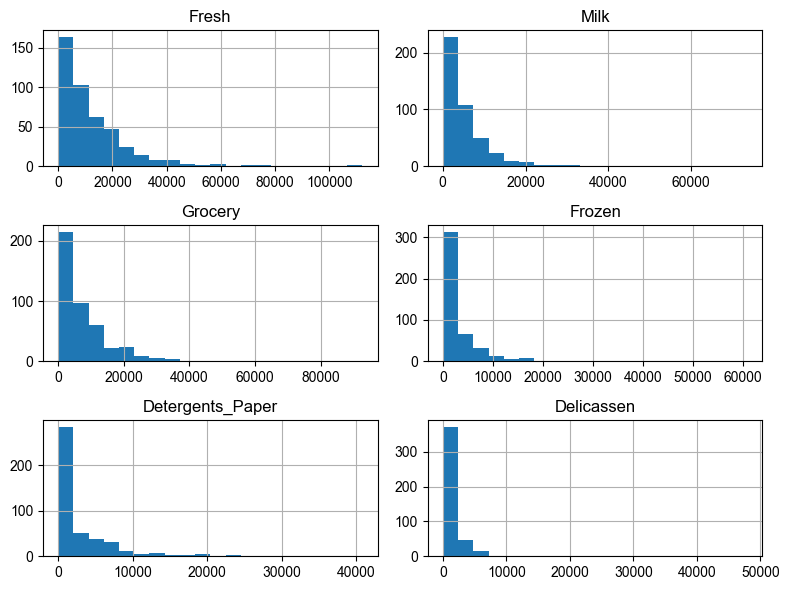

In [8]:
X.hist(bins=20, figsize=(8, 6))
plt.tight_layout()
plt.show()

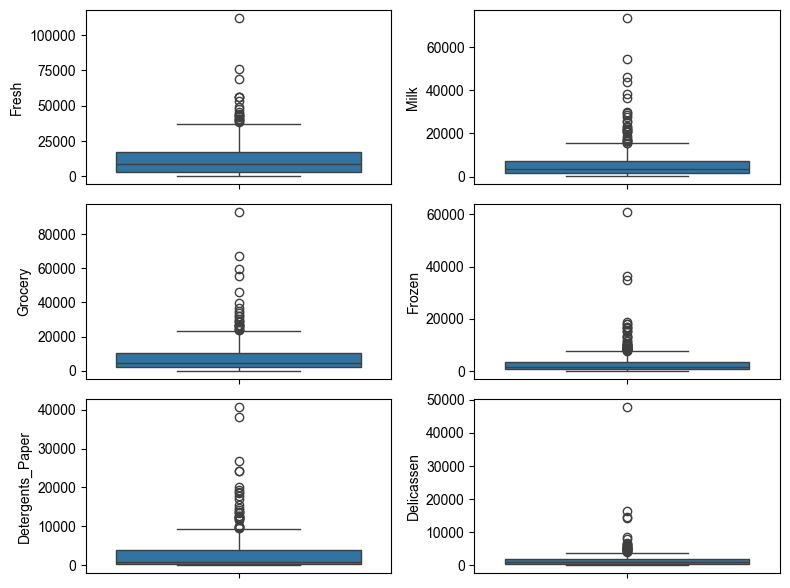

In [9]:
import seaborn as sns
plt.figure(figsize=(8, 6))
for idx in range(6):
    plt.subplot(3, 2, idx + 1)          # idx+1 -> 1,2,3,4 (subplot comeca em 1)
    col = X.columns[idx]
    sns.boxplot(data=X, y=col)

plt.tight_layout()
plt.show()

In [10]:
X_lnha = np.log1p(X)

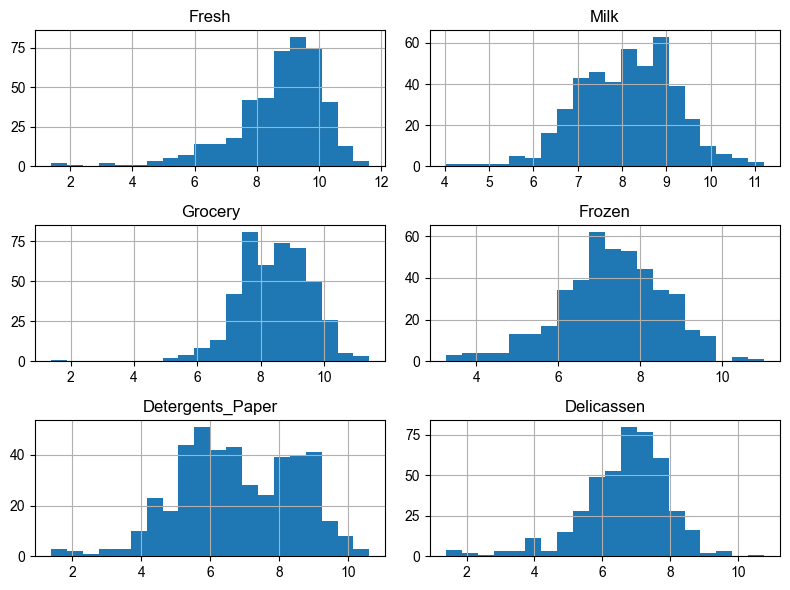

In [11]:
X_lnha.hist(bins=20, figsize=(8, 6))
plt.tight_layout()
plt.show()

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_lnha = scaler.fit_transform(X_lnha)

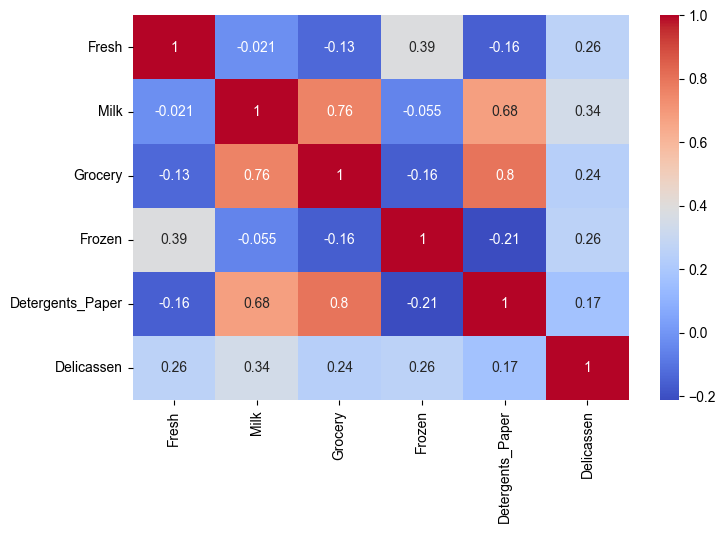

In [13]:
X_plot = pd.DataFrame(X_lnha, columns=X.columns, index=X.index)

corr = X_plot.corr() 
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

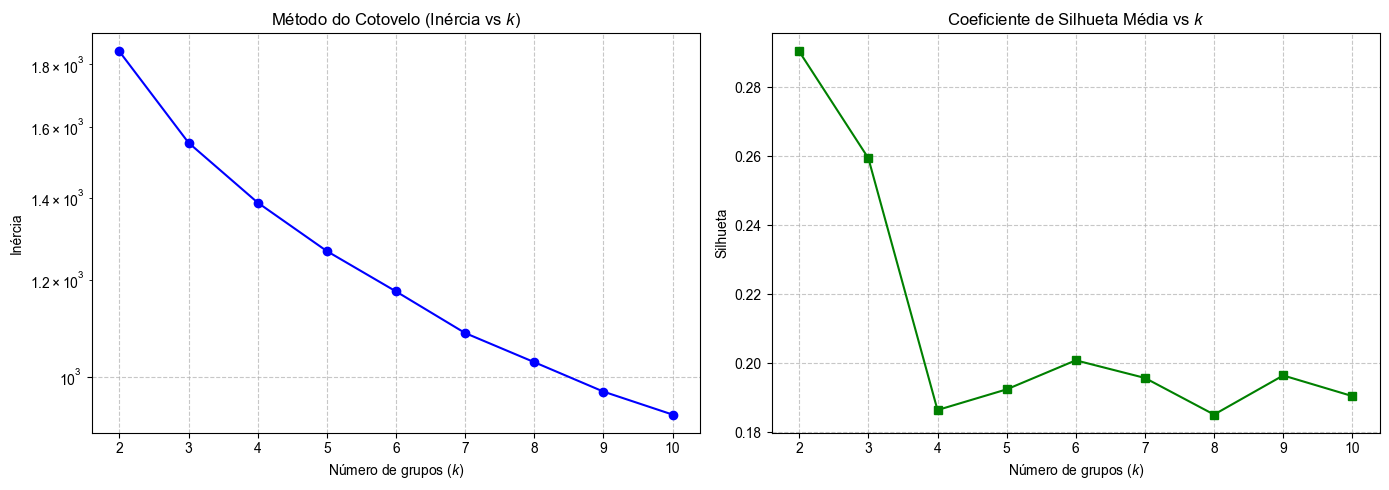

In [14]:
inercia = []
silhueta = []
k_valores = range(2, 11)

for k in k_valores:
    kmeans = KMeans(n_clusters=k, random_state=42, max_iter=100, tol=1e-3, n_init=10)
    kmeans.fit(X_lnha)
    
    inercia.append(kmeans.inertia_)
    silhueta.append(silhouette_score(X_lnha, kmeans.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_valores, inercia, marker='o', color='blue')
ax1.set_title('Método do Cotovelo (Inércia vs $k$)')
ax1.set_xlabel('Número de grupos ($k$)')
ax1.set_ylabel('Inércia')
ax1.set_yscale("log")
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.plot(k_valores, silhueta, marker='s', color='green')
ax2.set_title('Coeficiente de Silhueta Média vs $k$')
ax2.set_xlabel('Número de grupos ($k$)')
ax2.set_ylabel('Silhueta')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [15]:
modelo_my = KMeans(n_clusters=4, random_state=42, max_iter=100, tol=1e-3, n_init=10)
rotulos_my = modelo_my.fit_predict(X_lnha)

print(f"Inércia (myKMeans):     {modelo_my.inertia_:.4f}")
print(f"Iterações (melhor execução): {modelo_my.n_iter_}")

print("\nCentróides (ordenados pelo atributo 1):")
for c in modelo_my.cluster_centers_[np.argsort(modelo_my.cluster_centers_[:, 0])]:
    print(f"  ({c[0]:+.4f}, {c[1]:+.4f})")

Inércia (myKMeans):     1388.1021
Iterações (melhor execução): 8

Centróides (ordenados pelo atributo 1):
  (-1.2236, +0.4773)
  (-0.0414, -1.1128)
  (+0.1990, +0.9637)
  (+0.4507, -0.1763)


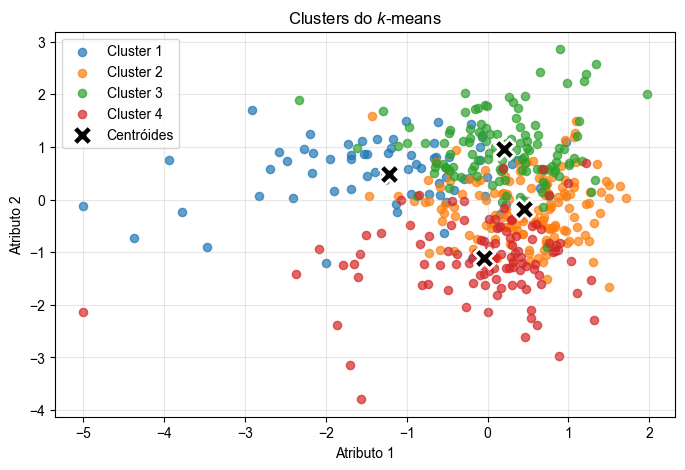

In [16]:
for c in range(4):
    mask = rotulos_my == c
    plt.scatter(X_lnha[mask, 0], X_lnha[mask, 1], s=35, alpha=0.7, label=f"Cluster {c+1}")
plt.scatter(modelo_my.cluster_centers_[:, 0], modelo_my.cluster_centers_[:, 1],
            marker="X", s=220, c="black", edgecolors="white", linewidths=2,
            label="Centróides", zorder=5)
plt.title("Clusters do $k$-means")
plt.xlabel("Atributo 1")
plt.ylabel("Atributo 2")
plt.legend()
plt.grid(alpha=0.3)

,Random,k-means++
0,1387.684789,1387.199977
1,1390.029903,1386.862741
2,1386.862741,1386.655066
3,1387.083868,1386.694349
4,1388.016928,1400.985184
5,1422.513813,1388.267365
6,1398.570269,1387.010202
7,1443.705830,1388.364864
8,1429.735003,1387.577953
9,1430.563034,1438.544650


--- Dispersão dos Resultados ---
Random Init* Desvio Padrão: 21.34 | Amplitude: 56.84
K-Means++- Desvio Padrão: 15.47 | Amplitude: 51.89


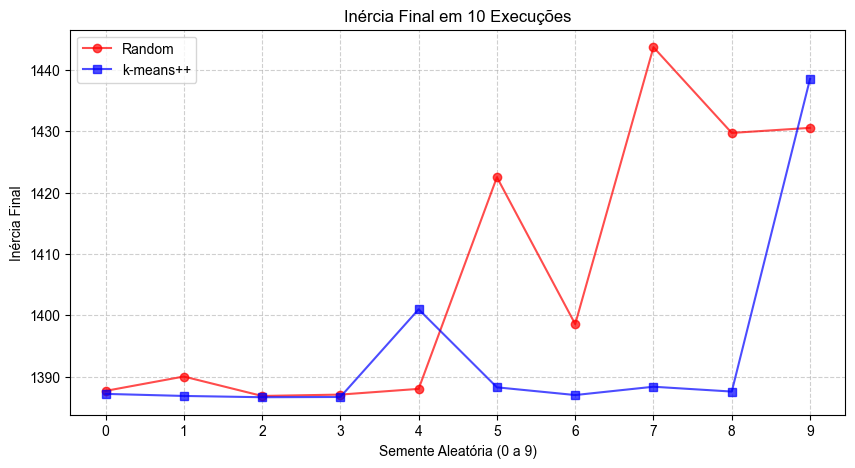

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_bichao = 4 

inercias_random = []
inercias_kmeansMM = []

for semente in range(10):
    kmeans_random = KMeans(n_clusters=k_bichao, init='random', n_init=1, random_state=semente)
    kmeans_random.fit(X_lnha)
    inercias_random.append(kmeans_random.inertia_)
    
    kmeans_pp = KMeans(n_clusters=k_bichao, init='k-means++', n_init=1, random_state=semente)
    kmeans_pp.fit(X_lnha)
    inercias_kmeansMM.append(kmeans_pp.inertia_)

df_comparacao = pd.DataFrame({
    'Random': inercias_random,
    'k-means++': inercias_kmeansMM
})
display(df_comparacao)

print("--- Dispersão dos Resultados ---")
print(f"Random Init* Desvio Padrão: {np.std(inercias_random):.2f} | Amplitude: {np.max(inercias_random) - np.min(inercias_random):.2f}")
print(f"K-Means++- Desvio Padrão: {np.std(inercias_kmeansMM):.2f} | Amplitude: {np.max(inercias_kmeansMM) - np.min(inercias_kmeansMM):.2f}")

plt.figure(figsize=(10, 5))
plt.plot(range(10), inercias_random, marker='o', linestyle='-', label="Random", color='red', alpha=0.7)
plt.plot(range(10), inercias_kmeansMM, marker='s', linestyle='-', label="k-means++", color='blue', alpha=0.7)
plt.title('Inércia Final em 10 Execuções')
plt.xlabel('Semente Aleatória (0 a 9)')
plt.ylabel('Inércia Final')
plt.xticks(range(10))
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Centróides na escala original (Gastos representativos em m.u.):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
perfil mercearia,1026.99,5634.16,9588.84,328.75,3117.12,283.40
perfil restaurante,12025.78,2781.99,3217.57,3181.44,439.67,1234.77
perfil varejo,8308.15,9525.41,13761.54,1530.38,4729.28,1857.18
perfil lanchonets,5836.36,1011.76,1474.20,1327.69,169.94,324.69


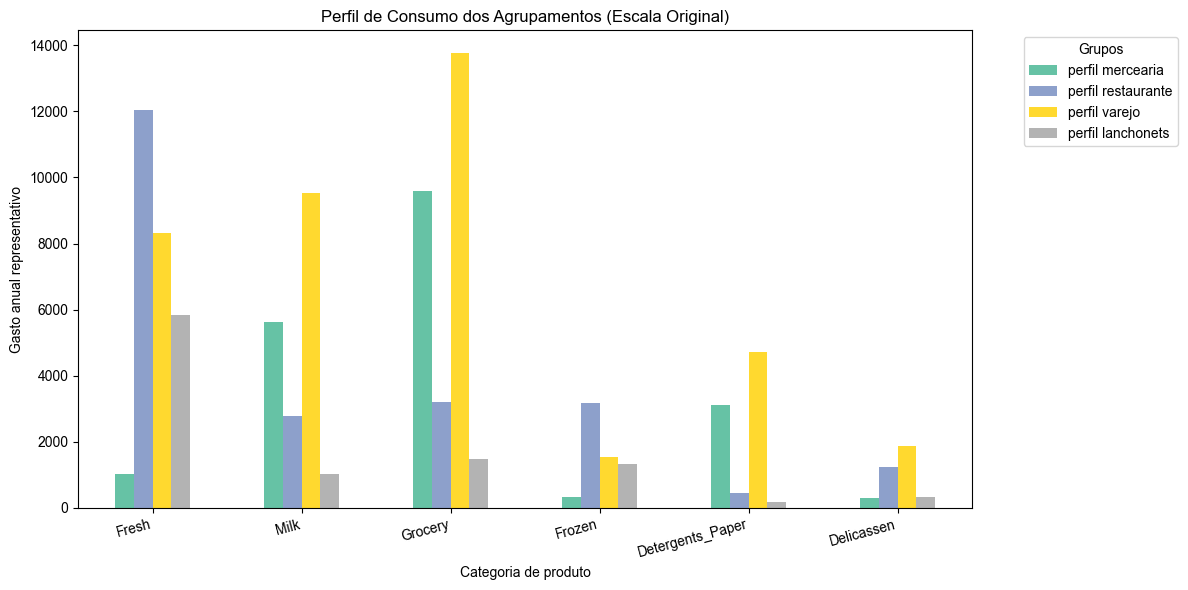

In [18]:
from sklearn.decomposition import PCA

centroides_padronizados = modelo_my.cluster_centers_
centroides_log = scaler.inverse_transform(centroides_padronizados)
centroides_originais = np.expm1(centroides_log)
# Média geométrica de (1 + gasto), menos 1; não é a média aritmética.

df_centroides = pd.DataFrame(centroides_originais, columns=X.columns)

nomes_grupos = ['perfil mercearia', 
                'perfil restaurante', 
                'perfil varejo', 
                'perfil lanchonets']
df_centroides.index = nomes_grupos

print("Centróides na escala original (Gastos representativos em m.u.):")
display(df_centroides.round(2))

df_centroides.T.plot(kind='bar', figsize=(12, 6), colormap='Set2')
plt.title('Perfil de Consumo dos Agrupamentos (Escala Original)')
plt.ylabel('Gasto anual representativo')
plt.xlabel('Categoria de produto')
plt.xticks(rotation=15, ha='right')
plt.legend(title='Grupos', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [19]:
rotulos = modelo_my.labels_

print("\nTabela de Contingência: Grupos x Channel (1=Horeca, 2=Retail)")
tabela_channel = pd.crosstab(index=rotulos, columns=y['Channel'], rownames=['Grupo (k-Means)'], colnames=['Channel'])
display(tabela_channel)

print("\nTabela de Contingência: Grupos x Region (1=Lisboa, 2=Porto, 3=Outras)")
tabela_region = pd.crosstab(index=rotulos, columns=y['Region'], rownames=['Grupo (k-Means)'], colnames=['Region'])
display(tabela_region)

ari_channel = adjusted_rand_score(y['Channel'], rotulos)
print(f"\nAdjusted Rand Index (Grupos vs Channel): {ari_channel:.4f}")


Tabela de Contingência: Grupos x Channel (1=Horeca, 2=Retail)


Channel,1,2
Grupo (k-Means),,
0,29,41
1,140,8
2,22,93
3,107,0



Tabela de Contingência: Grupos x Region (1=Lisboa, 2=Porto, 3=Outras)


Region,1,2,3
Grupo (k-Means),,,
0,11,7,52
1,29,17,102
2,18,13,84
3,19,10,78



Adjusted Rand Index (Grupos vs Channel): 0.2671


In [20]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_lnha)

pesos_pca = pd.DataFrame(
    pca.components_, 
    columns=X.columns, 
    index=['Componente Principal 1', 'Componente Principal 2']
)

print("Pesos PCA")
display(pesos_pca)

Pesos PCA


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Componente Principal 1,-0.105250,0.542329,0.571472,-0.137910,0.550642,0.214469
Componente Principal 2,0.590359,0.132911,-0.005751,0.589778,-0.070822,0.530022


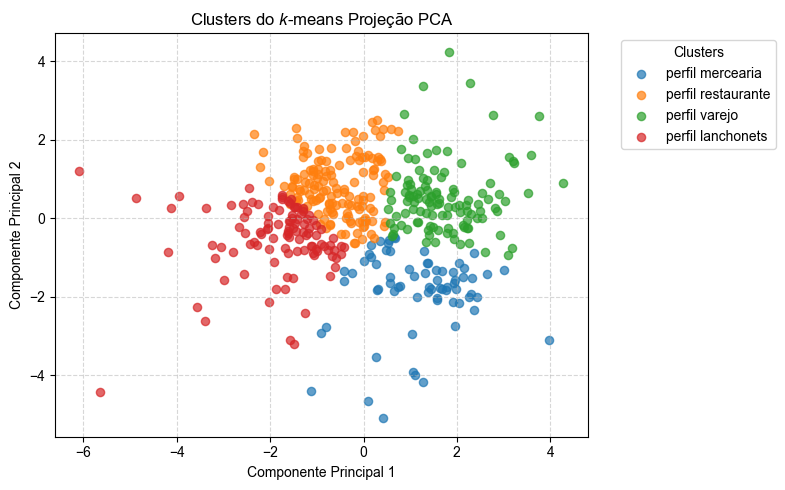

In [21]:
for c in range(4):
    mask = rotulos_my == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=35, alpha=0.7, label=nomes_grupos[c])

plt.title("Clusters do $k$-means Projeção PCA")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")

plt.legend(title="Clusters", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()